# Where do the models go wrong

Uses `results/predictions_test.csv` from `train.py`. Test = 2025.

In [1]:
import sys
sys.path.append("../src")

import matplotlib.pyplot as plt
import pandas as pd

from config import FIGURES_DIR, RESULTS_DIR
from features import make_features

plt.rcParams["figure.figsize"] = (10, 4)

In [2]:
metrics = pd.read_csv(RESULTS_DIR / "metrics.csv")
metrics.pivot(index="model", columns="split", values="mae").sort_values("test")

split,airgradient,test,val
model,,,
LightGBM + AirCast weights,6.34,6.39,9.03
LightGBM,6.98,6.84,8.87
baseline (tomorrow = today),7.15,8.83,9.16
linear regression,8.16,9.55,9.52
CAMS,11.24,10.19,10.41


In [3]:
metrics[metrics.split == "test"].sort_values("mae")

,model,split,mae,rmse,category_acc,n_days,note
9,LightGBM + AirCast weights,test,6.39,10.45,0.917,314,trained on train+val
7,LightGBM,test,6.84,11.52,0.924,314,trained on train+val
1,baseline (tomorrow = today),test,8.83,15.10,0.888,313,NaN
5,linear regression,test,9.55,12.88,0.876,314,trained on train+val
3,CAMS,test,10.19,18.13,0.879,314,NaN


In [4]:
pred = pd.read_csv(RESULTS_DIR / "predictions_test.csv", parse_dates=["date"])
pred.head()

,date,actual,baseline,cams,linear,lightgbm,lightgbm_weighted
0,2025-01-01,23.291667,91.478261,34.887500,46.124331,41.244993,43.994004
1,2025-01-02,73.041667,23.291667,31.475000,42.784173,46.714150,58.800677
2,2025-01-03,52.708333,73.041667,43.345833,66.743263,56.020268,57.648266
3,2025-01-04,30.208333,52.708333,37.483333,44.417204,27.027853,29.618432
4,2025-01-05,56.291667,30.208333,39.375000,60.049048,60.505104,66.093698


In [5]:
models = [c for c in pred.columns if c not in ("date", "actual")]
models

['baseline', 'cams', 'linear', 'lightgbm', 'lightgbm_weighted']

## Forecast vs reality, test winter

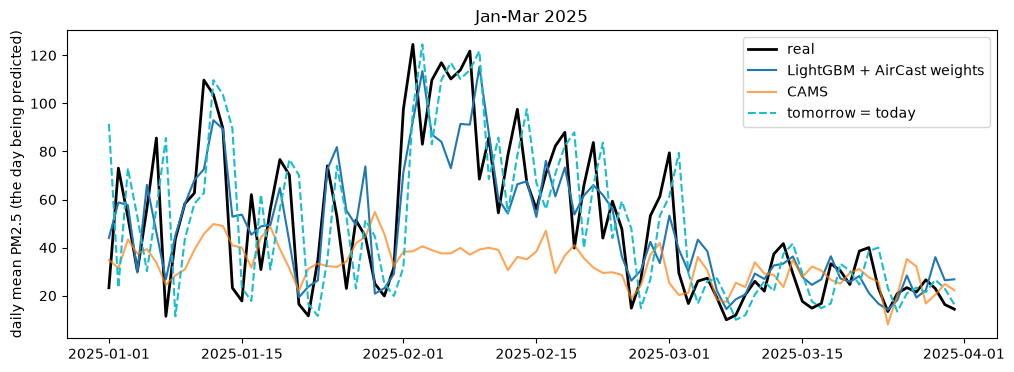

In [6]:
w = pred[pred.date < "2025-04-01"]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(w.date, w.actual, color="black", linewidth=2, label="real")
ax.plot(w.date, w.lightgbm_weighted, color="tab:blue", label="LightGBM + AirCast weights")
ax.plot(w.date, w.cams, color="tab:orange", label="CAMS", alpha=0.7)
ax.plot(w.date, w.baseline, color="tab:cyan", label="tomorrow = today", linestyle="--")
ax.set_ylabel("daily mean PM2.5 (the day being predicted)")
ax.set_title("Jan-Mar 2025")
ax.legend()
fig.savefig(FIGURES_DIR / "forecast_vs_real.png", dpi=120, bbox_inches="tight")

## Before and after the AirCast weights

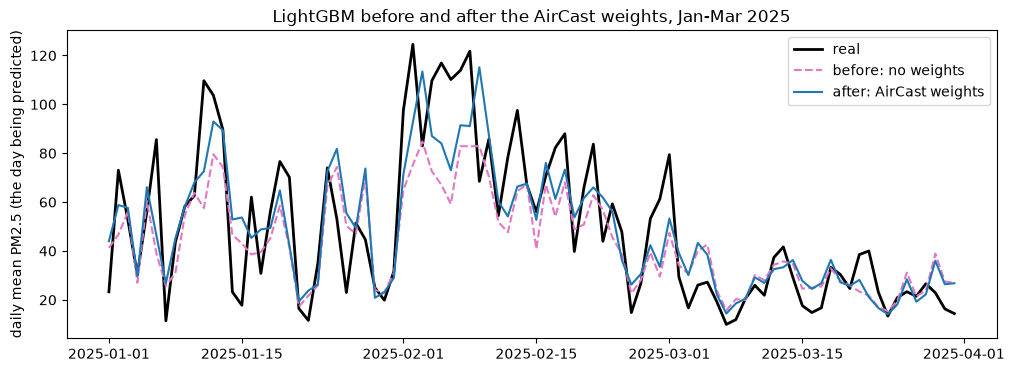

In [7]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(w.date, w.actual, color="black", linewidth=2, label="real")
ax.plot(w.date, w.lightgbm, color="tab:pink", linestyle="--", label="before: no weights")
ax.plot(w.date, w.lightgbm_weighted, color="tab:blue", label="after: AirCast weights")
ax.set_ylabel("daily mean PM2.5 (the day being predicted)")
ax.set_title("LightGBM before and after the AirCast weights, Jan-Mar 2025")
ax.legend()
fig.savefig(FIGURES_DIR / "weights_before_after.png", dpi=120, bbox_inches="tight")

Text(0, 0.5, 'LightGBM')

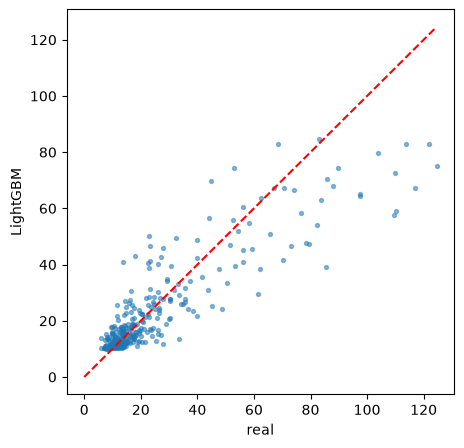

In [8]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(pred.actual, pred.lightgbm, s=8, alpha=0.5)
lim = pred[["actual", "lightgbm"]].max().max()
ax.plot([0, lim], [0, lim], color="red", linestyle="--")
ax.set_xlabel("real")
ax.set_ylabel("LightGBM")

## Worst days
Careful: the row date is the day the forecast was made, the target is the next day.

In [9]:
daily = make_features()
pred["error"] = pred.lightgbm - pred.actual
worst = pred.reindex(pred.error.abs().sort_values(ascending=False).index).head(10)
worst = worst.merge(daily, on="date", how="left")
worst[["date", "actual", "lightgbm", "error", "pm25_mean24h", "temp", "tmr_temp",
       "tmr_wind", "tmr_blh", "tmr_precipitation", "tmr_holiday"]].set_index("date").round(1)

,actual,lightgbm,error,pm25_mean24h,temp,tmr_temp,tmr_wind,tmr_blh,tmr_precipitation,tmr_holiday
date,,,,,,,,,,
2025-01-11,109.7,57.6,-52.1,62.7,-8.2,-7.7,4.2,44.6,0.0,0
2025-02-06,110.2,59.2,-50.9,116.9,-7.2,-5.5,2.8,30.6,0.0,0
2025-02-05,116.9,67.1,-49.8,109.7,-8.6,-7.2,2.3,33.8,0.0,0
2025-02-02,124.5,75.3,-49.3,97.5,-9.1,-9.2,6.1,74.6,0.0,0
2025-01-06,85.6,39.1,-46.5,56.3,-1.7,-1.6,3.4,67.3,0.5,1
2025-02-08,121.8,82.9,-38.9,113.9,-6.0,-5.1,2.4,43.8,0.0,0
2025-02-04,109.7,72.6,-37.1,83.0,-9.3,-8.6,3.2,47.7,0.0,0
2025-02-13,97.5,64.4,-33.1,78.4,-2.8,-4.4,2.8,77.7,0.0,0
2025-02-01,97.5,65.0,-32.5,31.7,-6.9,-9.1,2.9,71.7,0.0,0


In [10]:
# error by month: is it only winter that is hard?
pred.assign(abs_error=pred.error.abs()).groupby(pred.date.dt.month).abs_error.mean().round(1)

date
1     15.3
2     21.1
3      8.0
4      3.9
5      2.8
6      3.7
7      2.0
8      1.3
9      3.6
10     5.7
11    11.4
Name: abs_error, dtype: float64

<Axes: xlabel='jump', ylabel='error'>

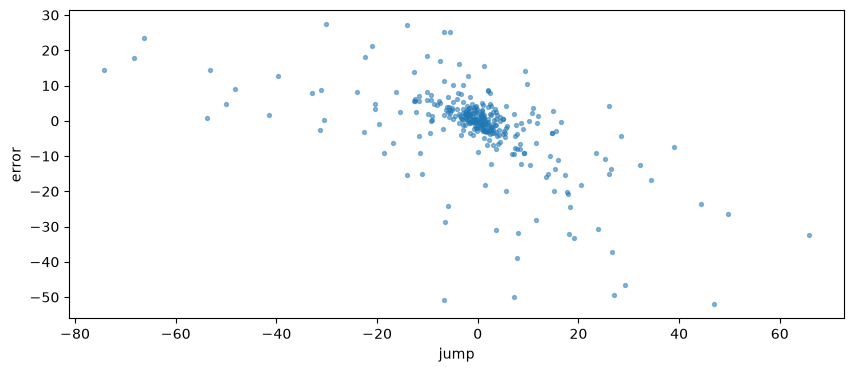

In [11]:
# does the model miss more when smog suddenly jumps or suddenly drops?
pred["jump"] = pred.actual - daily.set_index("date").pm25_mean24h.reindex(pred.date).values
pred.plot.scatter(x="jump", y="error", s=8, alpha=0.5)